In [1]:
# ============================================================
# RISKWEAVE WEATHER FORECASTING
# NOTEBOOK 01: WEATHER DATA INSPECTION
# CELL 1: LIBRARIES AND PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os

# ------------------------------------------------------------
# 1. Locate RiskWeave project root
# ------------------------------------------------------------

EXPECTED_DATA_PATH = (
    Path("data")
    / "raw"
    / "weather_era5_2006_2025"
    / "weather_daily_era5_2006-12-23_to_2025-12-19.csv"
)

PROJECT_ROOT = None

for folder in [Path.cwd(), *Path.cwd().parents]:

    if (folder / EXPECTED_DATA_PATH).exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:

    raise FileNotFoundError(
        "RiskWeave project root not found. "
        "Check your VS Code project directory."
    )

# ------------------------------------------------------------
# 2. Dataset paths
# ------------------------------------------------------------

DAILY_WEATHER_PATH = PROJECT_ROOT / EXPECTED_DATA_PATH

WEEKLY_WEATHER_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dengue_weather_weekly_25_districts.csv"
)

# ------------------------------------------------------------
# 3. Output directories
# ------------------------------------------------------------

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "outputs"
    / "weather_forecasting"
)

REPORT_DIR = OUTPUT_ROOT / "data_inspection"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. Display project information
# ------------------------------------------------------------

print("=" * 65)
print("RISKWEAVE WEATHER FORECASTING")
print("=" * 65)

print("\nPROJECT ROOT:")
print(PROJECT_ROOT)

print("\nDAILY DATASET:")
print(DAILY_WEATHER_PATH)

print("\nWEEKLY DATASET:")
print(WEEKLY_WEATHER_PATH)

print("\nFILE EXISTENCE CHECK")

print(
    "Daily dataset:",
    DAILY_WEATHER_PATH.exists()
)

print(
    "Weekly dataset:",
    WEEKLY_WEATHER_PATH.exists()
)

print("\nOUTPUT DIRECTORY:")
print(REPORT_DIR)

print("\nConfiguration completed.")

RISKWEAVE WEATHER FORECASTING

PROJECT ROOT:
c:\Users\ASUS\Documents\GitHub\RiskWeave

DAILY DATASET:
c:\Users\ASUS\Documents\GitHub\RiskWeave\data\raw\weather_era5_2006_2025\weather_daily_era5_2006-12-23_to_2025-12-19.csv

WEEKLY DATASET:
c:\Users\ASUS\Documents\GitHub\RiskWeave\data\processed\dengue_weather_weekly_25_districts.csv

FILE EXISTENCE CHECK
Daily dataset: True
Weekly dataset: True

OUTPUT DIRECTORY:
c:\Users\ASUS\Documents\GitHub\RiskWeave\outputs\weather_forecasting\data_inspection

Configuration completed.


In [2]:
# ============================================================
# CELL 2: LOAD DAILY AND WEEKLY WEATHER DATASETS
# ============================================================

# Load daily ERA5 weather data
daily_weather = pd.read_csv(DAILY_WEATHER_PATH)

# Load weekly dengue-weather data
weekly_weather = pd.read_csv(WEEKLY_WEATHER_PATH)

# ------------------------------------------------------------
# Display loading information
# ------------------------------------------------------------

print("=" * 65)
print("DATASET LOADING SUMMARY")
print("=" * 65)

print("\nDAILY WEATHER DATASET")
print("-" * 40)

print("Successfully loaded:", DAILY_WEATHER_PATH.name)
print("Number of records:", daily_weather.shape[0])
print("Number of columns:", daily_weather.shape[1])

print("\nWEEKLY WEATHER DATASET")
print("-" * 40)

print("Successfully loaded:", WEEKLY_WEATHER_PATH.name)
print("Number of records:", weekly_weather.shape[0])
print("Number of columns:", weekly_weather.shape[1])

# ------------------------------------------------------------
# Display first five records
# ------------------------------------------------------------

print("\nFIRST FIVE DAILY RECORDS")

display(daily_weather.head())

print("\nFIRST FIVE WEEKLY RECORDS")

display(weekly_weather.head())

print("\nBoth datasets loaded successfully.")

DATASET LOADING SUMMARY

DAILY WEATHER DATASET
----------------------------------------
Successfully loaded: weather_daily_era5_2006-12-23_to_2025-12-19.csv
Number of records: 173425
Number of columns: 25

WEEKLY WEATHER DATASET
----------------------------------------
Successfully loaded: dengue_weather_weekly_25_districts.csv
Number of records: 24775
Number of columns: 27

FIRST FIVE DAILY RECORDS


,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,...,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
0,Ampara,2006-12-23,6.8,6.8,22.0,25.3,27.1,24.2,89,94,...,99,13.74,2.80,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
1,Ampara,2006-12-24,3.4,3.4,19.0,25.6,27.3,23.8,87,94,...,97,11.36,2.60,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
2,Ampara,2006-12-25,3.8,3.8,11.0,25.2,26.4,24.0,83,87,...,100,6.42,2.08,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
3,Ampara,2006-12-26,1.3,1.3,8.0,25.5,27.4,23.6,81,89,...,98,12.89,3.19,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
4,Ampara,2006-12-27,0.0,0.0,0.0,25.4,28.0,23.5,77,84,...,93,14.11,3.48,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo



FIRST FIVE WEEKLY RECORDS


,district_key,week_start,week_end,dengue_cases,reporting_period_days,source_reporting_rows,source_areas,weather_days_observed,weather_days_expected,weather_days_complete,...,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,cloud_cover_mean,wind_direction_10m_dominant
0,ampara,2006-12-23,2006-12-29,0,7,2,Ampara | Kalmune,7,7,True,...,27.528571,23.571429,79.857143,87.285714,70.571429,21.471429,15.685714,21.085714,89.142857,8.574025
1,ampara,2006-12-30,2007-01-05,0,7,2,Ampara | Kalmune,7,7,True,...,28.042857,21.385714,71.142857,82.428571,57.000000,18.885714,14.485714,19.614286,59.428571,358.285579
2,ampara,2007-01-06,2007-01-12,0,7,2,Ampara | Kalmune,7,7,True,...,26.957143,23.271429,86.285714,92.285714,78.714286,22.285714,14.842857,18.828571,78.285714,20.694632
3,ampara,2007-01-13,2007-01-19,0,7,2,Ampara | Kalmune,7,7,True,...,27.728571,23.571429,83.142857,89.714286,74.571429,22.357143,17.114286,23.000000,77.857143,11.275426
4,ampara,2007-01-20,2007-01-26,0,7,2,Ampara | Kalmune,7,7,True,...,27.814286,22.742857,76.714286,85.142857,66.142857,20.600000,15.514286,20.385714,71.142857,7.286656



Both datasets loaded successfully.


In [3]:
# ============================================================
# CELL 3: INSPECT COLUMN NAMES AND DATA TYPES
# ============================================================

# Display all daily dataset columns
print("=" * 65)
print("DAILY WEATHER DATASET - COLUMN INFORMATION")
print("=" * 65)

for i, column in enumerate(daily_weather.columns, start=1):

    print(
        f"{i:02d}. {column:<40} "
        f"{daily_weather[column].dtype}"
    )

# Display all weekly dataset columns
print("\n" + "=" * 65)
print("WEEKLY WEATHER DATASET - COLUMN INFORMATION")
print("=" * 65)

for i, column in enumerate(weekly_weather.columns, start=1):

    print(
        f"{i:02d}. {column:<40} "
        f"{weekly_weather[column].dtype}"
    )

# ------------------------------------------------------------
# Display dataset information
# ------------------------------------------------------------

print("\nDAILY DATASET INFORMATION")

daily_weather.info()

print("\nWEEKLY DATASET INFORMATION")

weekly_weather.info()

DAILY WEATHER DATASET - COLUMN INFORMATION
01. district                                 object
02. date                                     object
03. precipitation_sum                        float64
04. rain_sum                                 float64
05. precipitation_hours                      float64
06. temperature_2m_mean                      float64
07. temperature_2m_max                       float64
08. temperature_2m_min                       float64
09. relative_humidity_2m_mean                int64
10. relative_humidity_2m_max                 int64
11. relative_humidity_2m_min                 int64
12. dew_point_2m_mean                        float64
13. wind_speed_10m_mean                      float64
14. wind_speed_10m_max                       float64
15. wind_direction_10m_dominant              int64
16. cloud_cover_mean                         int64
17. shortwave_radiation_sum                  float64
18. et0_fao_evapotranspiration               float64
19. requested_l

In [4]:
# ============================================================
# CELL 4: DATE CONVERSION AND VERIFICATION
# ============================================================

# Convert daily date column
daily_weather["date"] = pd.to_datetime(
    daily_weather["date"],
    errors="coerce"
)

# Convert weekly date columns
weekly_weather["week_start"] = pd.to_datetime(
    weekly_weather["week_start"],
    errors="coerce"
)

weekly_weather["week_end"] = pd.to_datetime(
    weekly_weather["week_end"],
    errors="coerce"
)

# ------------------------------------------------------------
# Check date conversion
# ------------------------------------------------------------

print("=" * 65)
print("DATE CONVERSION SUMMARY")
print("=" * 65)

print("\nDAILY WEATHER DATASET")

print("Data type:", daily_weather["date"].dtype)

print("Invalid dates:",
      daily_weather["date"].isna().sum())

print("First date:",
      daily_weather["date"].min())

print("Last date:",
      daily_weather["date"].max())

print("\nWEEKLY WEATHER DATASET")

for column in ["week_start", "week_end"]:

    print(f"\n{column}")

    print("Data type:", weekly_weather[column].dtype)

    print("Invalid dates:",
          weekly_weather[column].isna().sum())

    print("First date:", weekly_weather[column].min())

    print("Last date:", weekly_weather[column].max())

print("\nDate conversion completed.")

DATE CONVERSION SUMMARY

DAILY WEATHER DATASET
Data type: datetime64[ns]
Invalid dates: 0
First date: 2006-12-23 00:00:00
Last date: 2025-12-19 00:00:00

WEEKLY WEATHER DATASET

week_start
Data type: datetime64[ns]
Invalid dates: 0
First date: 2006-12-23 00:00:00
Last date: 2025-12-13 00:00:00

week_end
Data type: datetime64[ns]
Invalid dates: 0
First date: 2006-12-29 00:00:00
Last date: 2025-12-19 00:00:00

Date conversion completed.


MISSING VALUE ANALYSIS

DAILY WEATHER DATASET


,Missing_Count,Missing_Percentage
district,0,0.0
date,0,0.0
precipitation_sum,0,0.0
rain_sum,0,0.0
precipitation_hours,0,0.0
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
relative_humidity_2m_mean,0,0.0
relative_humidity_2m_max,0,0.0



Total missing daily values: 0

WEEKLY WEATHER DATASET


,Missing_Count,Missing_Percentage
district_key,0,0.0
week_start,0,0.0
week_end,0,0.0
dengue_cases,0,0.0
reporting_period_days,0,0.0
source_reporting_rows,0,0.0
source_areas,0,0.0
weather_days_observed,0,0.0
weather_days_expected,0,0.0
weather_days_complete,0,0.0



Total missing weekly values: 0


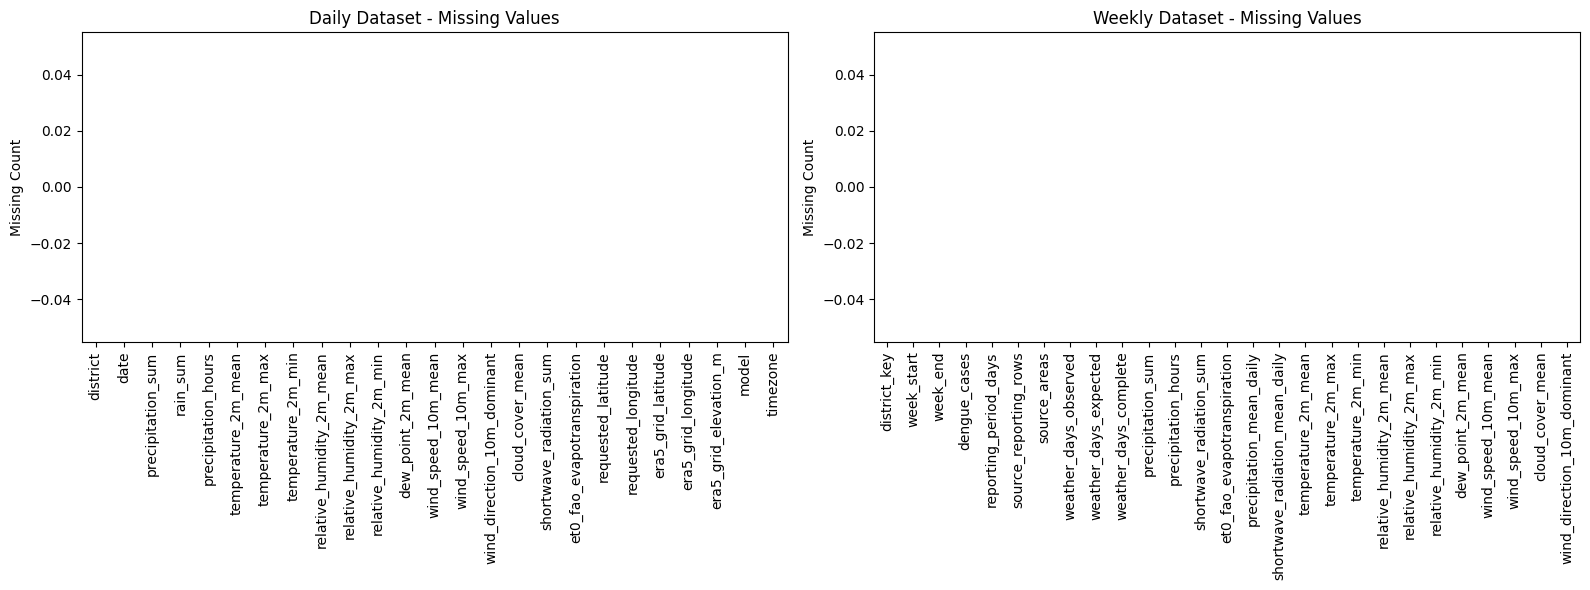

In [5]:
# ============================================================
# CELL 5: MISSING VALUE ANALYSIS
# ============================================================

print("=" * 65)
print("MISSING VALUE ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Daily dataset
# ------------------------------------------------------------

daily_missing = pd.DataFrame({
    "Missing_Count": daily_weather.isnull().sum(),
    "Missing_Percentage": (
        daily_weather.isnull().mean() * 100
    ).round(2)
})

daily_missing = daily_missing.sort_values(
    by="Missing_Count",
    ascending=False
)

print("\nDAILY WEATHER DATASET")

display(daily_missing)

print(
    "\nTotal missing daily values:",
    daily_weather.isnull().sum().sum()
)

# ------------------------------------------------------------
# 2. Weekly dataset
# ------------------------------------------------------------

weekly_missing = pd.DataFrame({
    "Missing_Count": weekly_weather.isnull().sum(),
    "Missing_Percentage": (
        weekly_weather.isnull().mean() * 100
    ).round(2)
})

weekly_missing = weekly_missing.sort_values(
    by="Missing_Count",
    ascending=False
)

print("\nWEEKLY WEATHER DATASET")

display(weekly_missing)

print(
    "\nTotal missing weekly values:",
    weekly_weather.isnull().sum().sum()
)

# ------------------------------------------------------------
# 3. Visualize missing values
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

daily_missing["Missing_Count"].plot(
    kind="bar",
    ax=axes[0],
    title="Daily Dataset - Missing Values"
)

weekly_missing["Missing_Count"].plot(
    kind="bar",
    ax=axes[1],
    title="Weekly Dataset - Missing Values"
)

axes[0].set_ylabel("Missing Count")
axes[1].set_ylabel("Missing Count")

plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# CELL 6: DUPLICATE RECORD ANALYSIS
# ============================================================

print("=" * 65)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Check complete duplicate rows
# ------------------------------------------------------------

daily_full_duplicates = daily_weather.duplicated().sum()

weekly_full_duplicates = weekly_weather.duplicated().sum()

print("\nCOMPLETE DUPLICATE ROWS")

print("Daily dataset:", daily_full_duplicates)

print("Weekly dataset:", weekly_full_duplicates)


# ------------------------------------------------------------
# 2. Check duplicate district-date combinations
# ------------------------------------------------------------

daily_key_duplicates = daily_weather.duplicated(
    subset=["district", "date"]
).sum()

print("\nDAILY DISTRICT-DATE DUPLICATES")

print("Duplicate records:", daily_key_duplicates)


# ------------------------------------------------------------
# 3. Check duplicate weekly district-period combinations
# ------------------------------------------------------------

weekly_key_duplicates = weekly_weather.duplicated(
    subset=["district_key", "week_start", "week_end"]
).sum()

print("\nWEEKLY DISTRICT-PERIOD DUPLICATES")

print("Duplicate records:", weekly_key_duplicates)


# ------------------------------------------------------------
# 4. Display duplicate records if they exist
# ------------------------------------------------------------

if daily_key_duplicates > 0:

    print("\nDaily duplicate examples:")

    display(
        daily_weather[
            daily_weather.duplicated(
                subset=["district", "date"],
                keep=False
            )
        ].head(10)
    )

if weekly_key_duplicates > 0:

    print("\nWeekly duplicate examples:")

    display(
        weekly_weather[
            weekly_weather.duplicated(
                subset=[
                    "district_key",
                    "week_start",
                    "week_end"
                ],
                keep=False
            )
        ].head(10)
    )


print("\nDuplicate analysis completed.")

DUPLICATE RECORD ANALYSIS

COMPLETE DUPLICATE ROWS
Daily dataset: 0
Weekly dataset: 0

DAILY DISTRICT-DATE DUPLICATES
Duplicate records: 0

WEEKLY DISTRICT-PERIOD DUPLICATES
Duplicate records: 0

Duplicate analysis completed.


In [7]:
# ============================================================
# CELL 7: DISTRICT COVERAGE ANALYSIS
# ============================================================

print("=" * 65)
print("DISTRICT COVERAGE ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Daily dataset district coverage
# ------------------------------------------------------------

daily_district_summary = (
    daily_weather.groupby("district")
    .agg(
        Record_Count=("date", "count"),
        First_Date=("date", "min"),
        Last_Date=("date", "max"),
        Unique_Dates=("date", "nunique")
    )
    .sort_index()
)

print("\nDAILY DATASET DISTRICT COVERAGE")

display(daily_district_summary)

print(
    "Number of districts:",
    daily_weather["district"].nunique()
)


# ------------------------------------------------------------
# 2. Weekly dataset district coverage
# ------------------------------------------------------------

weekly_district_summary = (
    weekly_weather.groupby("district_key")
    .agg(
        Record_Count=("week_start", "count"),
        First_Week=("week_start", "min"),
        Last_Week=("week_start", "max"),
        Unique_Weeks=("week_start", "nunique")
    )
    .sort_index()
)

print("\nWEEKLY DATASET DISTRICT COVERAGE")

display(weekly_district_summary)

print(
    "Number of districts:",
    weekly_weather["district_key"].nunique()
)


# ------------------------------------------------------------
# 3. Compare district names between datasets
# ------------------------------------------------------------

daily_districts = set(daily_weather["district"].unique())

weekly_districts = set(weekly_weather["district_key"].unique())

print("\nDISTRICT NAME COMPARISON")

print(
    "Districts only in daily dataset:",
    sorted(daily_districts - weekly_districts)
)

print(
    "Districts only in weekly dataset:",
    sorted(weekly_districts - daily_districts)
)

print("\nDistrict coverage analysis completed.")

DISTRICT COVERAGE ANALYSIS

DAILY DATASET DISTRICT COVERAGE


,Record_Count,First_Date,Last_Date,Unique_Dates
district,,,,
Ampara,6937,2006-12-23,2025-12-19,6937
Anuradhapura,6937,2006-12-23,2025-12-19,6937
Badulla,6937,2006-12-23,2025-12-19,6937
Batticaloa,6937,2006-12-23,2025-12-19,6937
Colombo,6937,2006-12-23,2025-12-19,6937
Galle,6937,2006-12-23,2025-12-19,6937
Gampaha,6937,2006-12-23,2025-12-19,6937
Hambantota,6937,2006-12-23,2025-12-19,6937
Jaffna,6937,2006-12-23,2025-12-19,6937


Number of districts: 25

WEEKLY DATASET DISTRICT COVERAGE


,Record_Count,First_Week,Last_Week,Unique_Weeks
district_key,,,,
ampara,991,2006-12-23,2025-12-13,991
anuradhapura,991,2006-12-23,2025-12-13,991
badulla,991,2006-12-23,2025-12-13,991
batticaloa,991,2006-12-23,2025-12-13,991
colombo,991,2006-12-23,2025-12-13,991
galle,991,2006-12-23,2025-12-13,991
gampaha,991,2006-12-23,2025-12-13,991
hambantota,991,2006-12-23,2025-12-13,991
jaffna,991,2006-12-23,2025-12-13,991


Number of districts: 25

DISTRICT NAME COMPARISON
Districts only in daily dataset: ['Ampara', 'Anuradhapura', 'Badulla', 'Batticaloa', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalutara', 'Kandy', 'Kegalle', 'Kilinochchi', 'Kurunegala', 'Mannar', 'Matale', 'Matara', 'Moneragala', 'Mullaitivu', 'Nuwara Eliya', 'Polonnaruwa', 'Puttalam', 'Ratnapura', 'Trincomalee', 'Vavuniya']
Districts only in weekly dataset: ['ampara', 'anuradhapura', 'badulla', 'batticaloa', 'colombo', 'galle', 'gampaha', 'hambantota', 'jaffna', 'kalutara', 'kandy', 'kegalle', 'kilinochchi', 'kurunegala', 'mannar', 'matale', 'matara', 'moneragala', 'mullaitivu', 'nuwaraeliya', 'polonnaruwa', 'puttalam', 'ratnapura', 'trincomalee', 'vavuniya']

District coverage analysis completed.


In [8]:
# ============================================================
# CELL 8: DAILY DATE CONTINUITY ANALYSIS
# ============================================================

print("=" * 65)
print("DAILY DATE CONTINUITY ANALYSIS")
print("=" * 65)

continuity_results = []

for district, group in daily_weather.groupby("district"):

    # Get sorted unique dates for this district
    actual_dates = pd.DatetimeIndex(
        group["date"].drop_duplicates().sort_values()
    )

    # Generate all expected calendar dates
    expected_dates = pd.date_range(
        start=actual_dates.min(),
        end=actual_dates.max(),
        freq="D"
    )

    # Identify dates that are missing
    missing_dates = expected_dates.difference(actual_dates)

    continuity_results.append({
        "District": district,
        "First_Date": actual_dates.min(),
        "Last_Date": actual_dates.max(),
        "Expected_Days": len(expected_dates),
        "Actual_Unique_Days": len(actual_dates),
        "Missing_Days": len(missing_dates),
        "Continuity_Status": (
            "Complete" if len(missing_dates) == 0 else "Gaps Found"
        )
    })

# Create results table
daily_continuity = pd.DataFrame(continuity_results)

daily_continuity = daily_continuity.sort_values("District")

display(daily_continuity)

# Overall summary
print("\nOVERALL SUMMARY")

print(
    "Total districts:",
    len(daily_continuity)
)

print(
    "Districts with complete date continuity:",
    (daily_continuity["Continuity_Status"] == "Complete").sum()
)

print(
    "Districts with date gaps:",
    (daily_continuity["Continuity_Status"] == "Gaps Found").sum()
)

print(
    "Total missing calendar days:",
    daily_continuity["Missing_Days"].sum()
)

print("\nDaily date continuity analysis completed.")

DAILY DATE CONTINUITY ANALYSIS


,District,First_Date,Last_Date,Expected_Days,Actual_Unique_Days,Missing_Days,Continuity_Status
0,Ampara,2006-12-23,2025-12-19,6937,6937,0,Complete
1,Anuradhapura,2006-12-23,2025-12-19,6937,6937,0,Complete
2,Badulla,2006-12-23,2025-12-19,6937,6937,0,Complete
3,Batticaloa,2006-12-23,2025-12-19,6937,6937,0,Complete
4,Colombo,2006-12-23,2025-12-19,6937,6937,0,Complete
5,Galle,2006-12-23,2025-12-19,6937,6937,0,Complete
6,Gampaha,2006-12-23,2025-12-19,6937,6937,0,Complete
7,Hambantota,2006-12-23,2025-12-19,6937,6937,0,Complete
8,Jaffna,2006-12-23,2025-12-19,6937,6937,0,Complete
9,Kalutara,2006-12-23,2025-12-19,6937,6937,0,Complete



OVERALL SUMMARY
Total districts: 25
Districts with complete date continuity: 25
Districts with date gaps: 0
Total missing calendar days: 0

Daily date continuity analysis completed.


In [9]:
# ============================================================
# CELL 9: WEEKLY PERIOD CONTINUITY ANALYSIS
# ============================================================

print("=" * 65)
print("WEEKLY PERIOD CONTINUITY ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Calculate actual period duration
# ------------------------------------------------------------

weekly_check = weekly_weather.copy()

weekly_check["Calculated_Period_Days"] = (
    weekly_check["week_end"] - weekly_check["week_start"]
).dt.days + 1

print("\nREPORTING PERIOD DURATION DISTRIBUTION")

duration_distribution = (
    weekly_check["Calculated_Period_Days"]
    .value_counts()
    .sort_index()
    .rename_axis("Period_Days")
    .reset_index(name="Record_Count")
)

display(duration_distribution)

# Compare with the existing reporting_period_days column
print("\nCOMPARISON WITH EXISTING PERIOD DURATION")

weekly_check["Duration_Matches_Source"] = (
    weekly_check["Calculated_Period_Days"]
    == weekly_check["reporting_period_days"]
)

print(
    "Records with matching duration:",
    weekly_check["Duration_Matches_Source"].sum()
)

print(
    "Records with duration mismatch:",
    (~weekly_check["Duration_Matches_Source"]).sum()
)


# ------------------------------------------------------------
# 2. Check continuity for each district
# ------------------------------------------------------------

weekly_continuity_results = []

for district, group in weekly_check.groupby("district_key"):

    group = group.sort_values("week_start").reset_index(drop=True)

    # Difference between the next period's start and
    # the previous period's end, in days.
    gap_days = (
        group["week_start"].iloc[1:].reset_index(drop=True)
        - group["week_end"].iloc[:-1].reset_index(drop=True)
    ).dt.days

    missing_days = (gap_days - 1).clip(lower=0).sum()
    overlap_days = (1 - gap_days).clip(lower=0).sum()

    weekly_continuity_results.append({
        "District": district,
        "Number_of_Periods": len(group),
        "First_Week": group["week_start"].min(),
        "Last_Week": group["week_end"].max(),
        "Missing_Days_Between_Periods": int(missing_days),
        "Overlapping_Days": int(overlap_days),
        "Continuity_Status": (
            "Complete"
            if missing_days == 0 and overlap_days == 0
            else "Issue Found"
        )
    })

weekly_continuity = pd.DataFrame(weekly_continuity_results)

print("\nWEEKLY DISTRICT CONTINUITY RESULTS")

display(weekly_continuity)


# ------------------------------------------------------------
# 3. Overall summary
# ------------------------------------------------------------

print("\nOVERALL WEEKLY CONTINUITY SUMMARY")

print(
    "Total districts:",
    len(weekly_continuity)
)

print(
    "Districts with complete continuity:",
    (
        weekly_continuity["Continuity_Status"] == "Complete"
    ).sum()
)

print(
    "Districts with continuity issues:",
    (
        weekly_continuity["Continuity_Status"] == "Issue Found"
    ).sum()
)

print(
    "Total missing days between periods:",
    weekly_continuity["Missing_Days_Between_Periods"].sum()
)

print(
    "Total overlapping days:",
    weekly_continuity["Overlapping_Days"].sum()
)

print("\nWeekly period continuity analysis completed.")

WEEKLY PERIOD CONTINUITY ANALYSIS

REPORTING PERIOD DURATION DISTRIBUTION


,Period_Days,Record_Count
0,6,25
1,7,24725
2,8,25



COMPARISON WITH EXISTING PERIOD DURATION
Records with matching duration: 24775
Records with duration mismatch: 0

WEEKLY DISTRICT CONTINUITY RESULTS


,District,Number_of_Periods,First_Week,Last_Week,Missing_Days_Between_Periods,Overlapping_Days,Continuity_Status
0,ampara,991,2006-12-23,2025-12-19,0,0,Complete
1,anuradhapura,991,2006-12-23,2025-12-19,0,0,Complete
2,badulla,991,2006-12-23,2025-12-19,0,0,Complete
3,batticaloa,991,2006-12-23,2025-12-19,0,0,Complete
4,colombo,991,2006-12-23,2025-12-19,0,0,Complete
5,galle,991,2006-12-23,2025-12-19,0,0,Complete
6,gampaha,991,2006-12-23,2025-12-19,0,0,Complete
7,hambantota,991,2006-12-23,2025-12-19,0,0,Complete
8,jaffna,991,2006-12-23,2025-12-19,0,0,Complete
9,kalutara,991,2006-12-23,2025-12-19,0,0,Complete



OVERALL WEEKLY CONTINUITY SUMMARY
Total districts: 25
Districts with complete continuity: 25
Districts with continuity issues: 0
Total missing days between periods: 0
Total overlapping days: 0

Weekly period continuity analysis completed.


In [12]:
# ============================================================
# CELL 10: WEATHER VARIABLE LOGICAL AND PHYSICAL CHECKS
# ============================================================

print("=" * 65)
print("WEATHER VARIABLE VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Descriptive statistics for important weather variables
# ------------------------------------------------------------

weather_variables = [
    "precipitation_sum",
    "rain_sum",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "cloud_cover_mean"
]

print("\nDAILY WEATHER VARIABLE SUMMARY")

display(
    daily_weather[weather_variables].describe().T.round(2)
)


# ------------------------------------------------------------
# 2. Temperature logical consistency
# ------------------------------------------------------------

temperature_min_max_issues = (
    daily_weather["temperature_2m_min"]
    > daily_weather["temperature_2m_max"]
).sum()

temperature_order_issues = (
    (daily_weather["temperature_2m_min"]
     > daily_weather["temperature_2m_mean"])
    |
    (daily_weather["temperature_2m_mean"]
     > daily_weather["temperature_2m_max"])
).sum()

print("\nTEMPERATURE CONSISTENCY")

print("Minimum temperature > maximum temperature:",
      temperature_min_max_issues)

print("Incorrect minimum-mean-maximum ordering:",
      temperature_order_issues)


# ------------------------------------------------------------
# 3. Relative humidity logical consistency
# ------------------------------------------------------------

humidity_order_issues = (
    (daily_weather["relative_humidity_2m_min"]
     > daily_weather["relative_humidity_2m_mean"])
    |
    (daily_weather["relative_humidity_2m_mean"]
     > daily_weather["relative_humidity_2m_max"])
).sum()

humidity_range_issues = (
    (daily_weather["relative_humidity_2m_min"] < 0)
    |
    (daily_weather["relative_humidity_2m_max"] > 100)
).sum()

print("\nRELATIVE HUMIDITY CONSISTENCY")

print("Incorrect minimum-mean-maximum ordering:",
      humidity_order_issues)

print("Values outside 0-100% range:",
      humidity_range_issues)


# ------------------------------------------------------------
# 4. Non-negative variable checks
# ------------------------------------------------------------

non_negative_variables = [
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration"
]

print("\nNON-NEGATIVE VARIABLE CHECKS")

for column in non_negative_variables:

    invalid_count = (daily_weather[column] < 0).sum()

    print(f"{column}: {invalid_count} negative values")


# ------------------------------------------------------------
# 5. Cloud cover range check
# ------------------------------------------------------------

cloud_cover_issues = (
    (daily_weather["cloud_cover_mean"] < 0)
    |
    (daily_weather["cloud_cover_mean"] > 100)
).sum()

print("\nCLOUD COVER CHECK")

print("Values outside 0-100%:", cloud_cover_issues)


# ------------------------------------------------------------
# 6. Compare precipitation_sum and rain_sum
# ------------------------------------------------------------

precipitation_difference = (
    daily_weather["precipitation_sum"]
    - daily_weather["rain_sum"]
).abs()

precipitation_mismatch_count = (
    precipitation_difference > 1e-9
).sum()

print("\nPRECIPITATION VARIABLE COMPARISON")

print("Mismatched records:", precipitation_mismatch_count)

print(
    "Maximum absolute difference:",
    precipitation_difference.max()
)


# ------------------------------------------------------------
# 7. Final validation summary
# ------------------------------------------------------------

print("\nWEATHER VARIABLE VALIDATION COMPLETED.")

WEATHER VARIABLE VALIDATION

DAILY WEATHER VARIABLE SUMMARY


,count,mean,std,min,25%,50%,75%,max
precipitation_sum,173425.0,5.37,10.41,0.0,0.1,1.6,6.4,310.4
rain_sum,173425.0,5.37,10.41,0.0,0.1,1.6,6.4,310.4
temperature_2m_mean,173425.0,26.18,3.31,8.5,25.4,26.6,28.1,32.9
temperature_2m_max,173425.0,30.00,3.65,10.3,28.6,30.3,32.1,41.1
temperature_2m_min,173425.0,23.37,3.45,4.0,22.3,24.0,25.5,30.6
relative_humidity_2m_mean,173425.0,80.82,8.28,36.0,75.0,82.0,87.0,99.0
relative_humidity_2m_max,173425.0,92.20,6.04,50.0,89.0,94.0,97.0,100.0
relative_humidity_2m_min,173425.0,64.64,12.52,13.0,56.0,66.0,74.0,98.0
wind_speed_10m_mean,173425.0,10.89,6.42,1.0,5.8,9.3,14.7,47.0
wind_speed_10m_max,173425.0,15.74,6.96,2.0,10.4,14.7,20.1,54.1



TEMPERATURE CONSISTENCY
Minimum temperature > maximum temperature: 0
Incorrect minimum-mean-maximum ordering: 0

RELATIVE HUMIDITY CONSISTENCY
Incorrect minimum-mean-maximum ordering: 0
Values outside 0-100% range: 0

NON-NEGATIVE VARIABLE CHECKS
precipitation_sum: 0 negative values
rain_sum: 0 negative values
precipitation_hours: 0 negative values
wind_speed_10m_mean: 0 negative values
wind_speed_10m_max: 0 negative values
shortwave_radiation_sum: 0 negative values
et0_fao_evapotranspiration: 0 negative values

CLOUD COVER CHECK
Values outside 0-100%: 0

PRECIPITATION VARIABLE COMPARISON
Mismatched records: 0
Maximum absolute difference: 0.0

WEATHER VARIABLE VALIDATION COMPLETED.
